# 09 — Comparaison des systèmes de recherche

Ce notebook compare les résultats de tous les systèmes (BM25, bi-encoder, reranker, distillation, hybride).


In [1]:
import sys
sys.path.insert(0, "..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from src.evaluation.results_io import load_metrics

# Palette de couleurs
COLORS = ['#e30513', '#ffc103', '#0099ff', '#515151', '#f7a941', '#51a27e', '#702e78', '#7b003d']

# Style matplotlib
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('seaborn-whitegrid')

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

## 1. Chargement des métriques de chaque système

Chemins vers les résultats de chaque système.

In [2]:
# Dictionnaire {nom_système: chemin_run_dir}
SYSTEM_DIRS = {
    # Baseline
    "BM25":                    "../results/baselines/bm25_msmarco_dev",
    # Dense retrieval
    "Dense BGE-base FT (10%)": "../results/dense/evaluation/dense_bge_base_ft_subset10_msmarco_dev",
    "Dense BGE-large (30%)":   "../results/dense/evaluation/dense_bge_large_subset30_msmarco_dev",
    # Mistral reranker
    "Mistral zero-shot":       "../results/mistral/evaluation/mistral_zero_shot_msmarco_dev",
    "Mistral LoRA r4":         "../results/mistral/evaluation/mistral_r4_msmarco_dev",
    "Mistral LoRA r8":         "../results/mistral/evaluation/mistral_r8_msmarco_dev",
    "Mistral LoRA r16":        "../results/mistral/evaluation/mistral_r16_msmarco_dev",
    # Cross-encoder
    "BGE-reranker ZS":         "../results/cross_encoder/evaluation/bge_reranker_zs_msmarco_dev",
    "BGE-reranker FT":         "../results/cross_encoder/evaluation/bge_reranker_ft_msmarco_dev",
    # PairDistill
    "PairDistill BGE-small":   "../results/pairdistill/evaluation/pairdistill_bge_small_subset10_msmarco_dev",
}

all_metrics = {}
for name, run_dir in SYSTEM_DIRS.items():
    try:
        all_metrics[name] = load_metrics(run_dir)
    except Exception:
        pass

print(f"Systèmes chargés : {list(all_metrics.keys())}")


Systèmes chargés : ['BM25', 'Dense BGE-base FT (10%)', 'Dense BGE-large (30%)', 'Mistral zero-shot', 'Mistral LoRA r4', 'Mistral LoRA r8', 'Mistral LoRA r16', 'BGE-reranker ZS', 'BGE-reranker FT', 'PairDistill BGE-small']


## 2. Comparaison MRR@10 par système

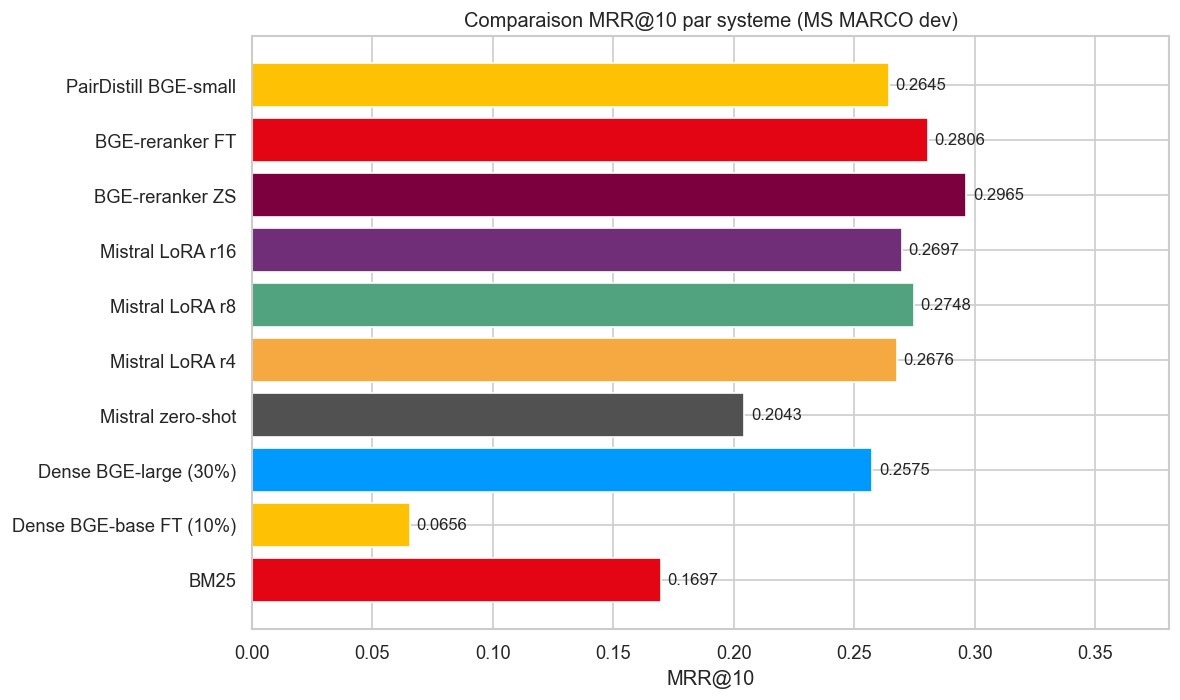

In [3]:
if all_metrics:
    systems = list(all_metrics.keys())
    mrr_values = [all_metrics[s].get("MRR@10", 0) for s in systems]

    OUT_DIR = Path("../results/analysis/08_global_comparison")
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(
        systems, mrr_values,
        color=[COLORS[i % len(COLORS)] for i in range(len(systems))],
        edgecolor="white"
    )
    ax.bar_label(bars, fmt="%.4f", padding=4, fontsize=10)
    ax.set_xlabel("MRR@10")
    ax.set_title("Comparaison MRR@10 par systeme (MS MARCO dev)")
    ax.set_xlim(0, max(mrr_values) * 1.25 + 0.01)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "mrr_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Aucun resultat disponible.")


## 3. Comparaison Recall@100 par système

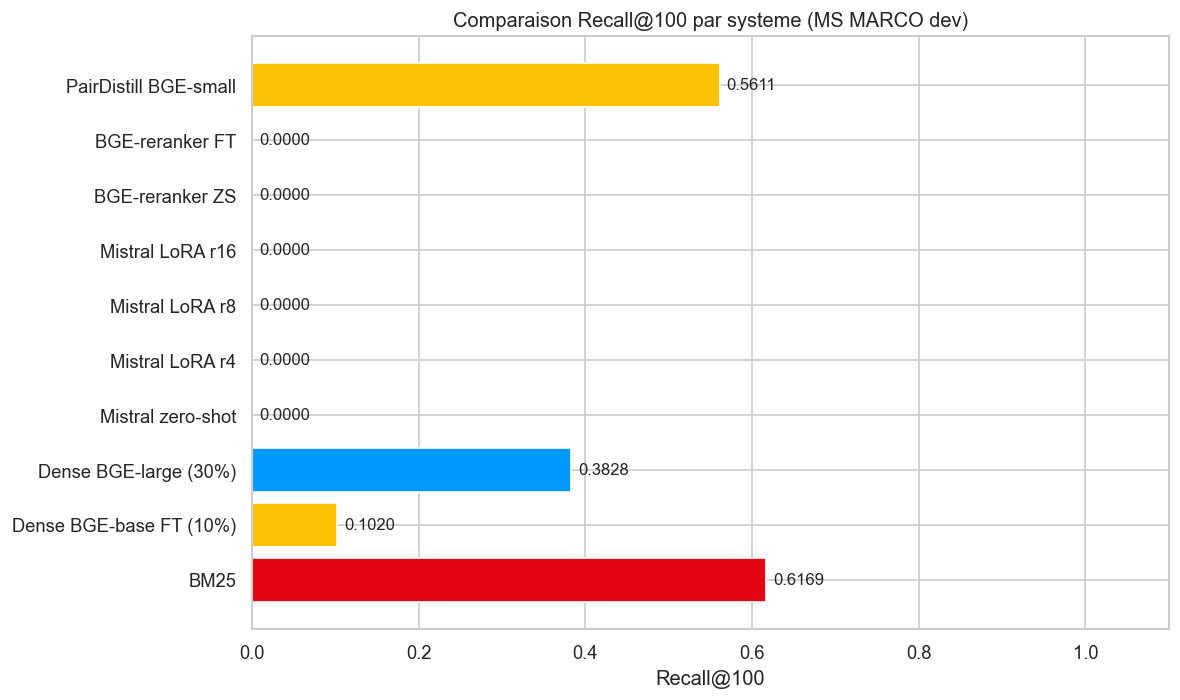

In [4]:
if all_metrics:
    recall100 = [all_metrics[s].get("Recall@100", 0) for s in systems]

    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(
        systems, recall100,
        color=[COLORS[i % len(COLORS)] for i in range(len(systems))],
        edgecolor="white"
    )
    ax.bar_label(bars, fmt="%.4f", padding=4, fontsize=10)
    ax.set_xlabel("Recall@100")
    ax.set_title("Comparaison Recall@100 par systeme (MS MARCO dev)")
    ax.set_xlim(0, 1.1)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "recall100_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()


## 4. Courbes d'apprentissage (training loss)

Historiques d'entraînement de chaque système.

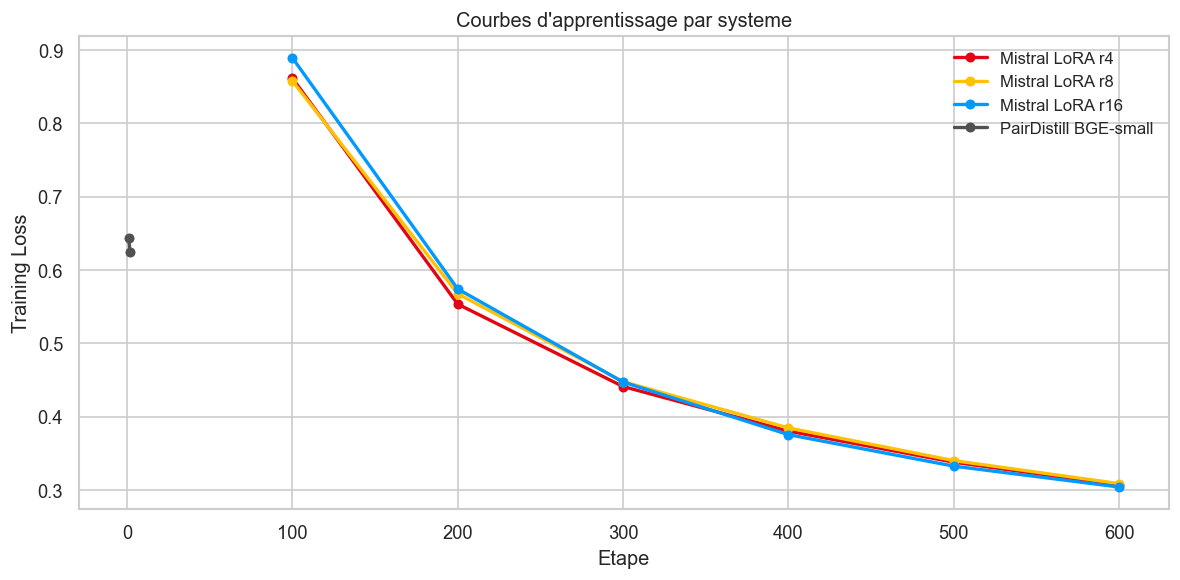

In [5]:
# Chargement des courbes d'apprentissage depuis les fichiers JSON
import json
from pathlib import Path

TRAIN_LOSS_FILES = {
    "Mistral LoRA r4":  "../results/mistral/training/mistral_lora_r4/training_loss.json",
    "Mistral LoRA r8":  "../results/mistral/training/mistral_lora_r8/training_loss.json",
    "Mistral LoRA r16": "../results/mistral/training/mistral_lora_r16/training_loss.json",
    "PairDistill BGE-small": "../models/pairdistill_bm25_10pct/pairdistill_training.json",
}

training_curves = {}
for name, fpath in TRAIN_LOSS_FILES.items():
    p = Path(fpath)
    if p.exists():
        data = json.loads(p.read_text())
        # Format liste [{step, loss}] ou dict {config, history:[{epoch, loss}]}
        if isinstance(data, dict) and "history" in data:
            data = data["history"]
        if data and isinstance(data, list):
            if "step" in data[0]:
                training_curves[name] = [(d["step"], d["loss"]) for d in data]
            elif "epoch" in data[0]:
                training_curves[name] = [(d["epoch"], d["loss"]) for d in data]

if training_curves:
    fig, ax = plt.subplots(figsize=(10, 5))
    for idx, (name, curve) in enumerate(training_curves.items()):
        xs, ys = zip(*curve)
        ax.plot(xs, ys, marker="o", label=name,
                color=COLORS[idx % len(COLORS)], linewidth=2, markersize=5)
    ax.set_xlabel("Etape")
    ax.set_ylabel("Training Loss")
    ax.set_title("Courbes d'apprentissage par systeme")
    ax.legend(fontsize=10)
    plt.tight_layout()
    OUT_DIR = Path("../results/analysis/08_global_comparison")
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    plt.savefig(OUT_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Aucune courbe d'apprentissage disponible.")


## 5. Analyse qualitative BM25 — exemples bien/mal traités

In [6]:
qual_path = Path("../results/baselines/bm25_msmarco_dev/qualitative_examples.json")
if qual_path.exists():
    examples = json.loads(qual_path.read_text())

    # Sépare les succès (rang 1 pertinent) et les échecs (aucun pertinent dans top-3)
    successes = [e for e in examples if e["retrieved"] and e["retrieved"][0]["relevant"]]
    failures  = [e for e in examples if not any(r["relevant"] for r in e["retrieved"][:3])]

    print(f"=== BM25 — Exemples réussis ({len(successes)}) ===")
    for ex in successes[:2]:
        print(f"  Q : {ex['query']}")
        print(f"  #1 (pertinent) : {ex['retrieved'][0]['text'][:150]}...\n")

    print(f"=== BM25 — Exemples échoués ({len(failures)}) ===")
    for ex in failures[:2]:
        print(f"  Q : {ex['query']}")
        print(f"  #1 (non pertinent) : {ex['retrieved'][0]['text'][:150]}...\n")
else:
    print("Lancez d'abord : python scripts/run_bm25_eval.py")

=== BM25 — Exemples réussis (0) ===
=== BM25 — Exemples échoués (10) ===
  Q : how many years did william bradford serve as governor of plymouth colony?
  #1 (non pertinent) : William Bradford (Mayflower passenger) William Bradford (1590 â 1657) was a passenger on the Mayflower in 1620. He travelled to the New World to liv...

  Q : define preventive
  #1 (non pertinent) : Electrical Preventive Maintenance Electrical Preventive Maintenance Electrical Preventive Maintenance Electrical Preventive Maintenance Electrical Pre...



## 6. Tableau récapitulatif

In [7]:
if all_metrics:
    print(f"{'Système':<25} {'MRR@10':>8} {'Recall@10':>10} {'Recall@100':>11} {'nDCG@10':>8}")
    print("-" * 65)
    for name, m in all_metrics.items():
        print(
            f"{name:<25} "
            f"{m.get('MRR@10', 0):>8.4f} "
            f"{m.get('Recall@10', 0):>10.4f} "
            f"{m.get('Recall@100', 0):>11.4f} "
            f"{m.get('nDCG@10', 0):>8.4f}"
        )

Système                     MRR@10  Recall@10  Recall@100  nDCG@10
-----------------------------------------------------------------
BM25                        0.1697     0.3578      0.6169   0.2127
Dense BGE-base FT (10%)     0.0656     0.0873      0.1020   0.0696
Dense BGE-large (30%)       0.2575     0.3389      0.3828   0.2760
Mistral zero-shot           0.2043     0.3843      0.0000   0.2457
Mistral LoRA r4             0.2676     0.4067      0.0000   0.3000
Mistral LoRA r8             0.2748     0.4275      0.0000   0.3099
Mistral LoRA r16            0.2697     0.4107      0.0000   0.3027
BGE-reranker ZS             0.2965     0.4342      0.0000   0.3274
BGE-reranker FT             0.2806     0.4318      0.0000   0.3150
PairDistill BGE-small       0.2645     0.3827      0.5611   0.2910
